# 11. 3단계 결과 — 지연이 아닌데도 저평점을 준 고객은 무엇에 불만을 가졌나

| 항목 | 내용 |
|---|---|
| 목적 | 3단계 결과 표와 라벨을 읽어 표·그림으로 정리하고, 숫자를 결과 문서와 assert로 대조(새로 계산하지 않음, kappa만 재계산) |
| 입력 | `outputs/tables/stage3_results_*.csv`, `stage3_holdout_rule_*.csv`, `outputs/labels/stage3_labels_dev.csv`(모두 원문 없음) |
| 출력 | `outputs/figures/11_stage3_shares.png`, `11_stage3_cross_p3_p1.png` |
| 관련 결정 | D-23\~D-35 |
| 핵심 결과 | P3 구성품 누락·오배송 32.9%, P1 품질·파손 25.2%, P6a 지연 언급 4.9% / H1·H2 기각, H3 판단불가 |

> **읽는 법**: 맨 아래 「결론」 셀에 최종 결과가 있다. 본문의 `[YYYY-MM-DD 정정·추가]` 표시는 고친 이력이며, 최종 판단은 결론 셀과 `docs/decisions.md`를 따른다.

---

## 설명

- **이 노트북은 3단계 결과를 보여 주는 곳이다. 새로 계산하지 않는다.** 집계는 `tools/` 스크립트가 했고, 이 노트북은 그 스크립트들이 저장한 **결과 표(원문 없음)** 를 읽어 표·그림으로 정리한다. kappa만 커밋된 라벨 파일에서 다시 계산해 `compute_kappa.py` 결과(0.864, D-32)와 맞춰 본다.
- 입력(모두 저장소에 커밋된 파일, 리뷰 원문·번역 없음): `outputs/tables/stage3_results_*.csv`, `outputs/tables/stage3_holdout_rule_*.csv`, `outputs/labels/stage3_labels_dev.csv`
- 셀마다 숫자가 결과 문서(`docs/stage3_results.md`)와 같은지 `assert`로 확인한다. 하나라도 어긋나면 멈춘다.
- 실행: VS Code에서 `olist` 폴더를 연 상태로 Restart & Run All(경로 기준 = 프로젝트 루트, E-04). 그림은 `outputs/figures/11_*.png`로 저장된다.
- 자세한 근거: 규칙 `docs/stage3_step0_rules.md`(라벨링 전 커밋), 코드북 `docs/stage3_codebook_v1.md`, 결정 `docs/decisions.md` D-23\~D-35, 작업 기록 `docs/log.md` Day 7\~11.

### 한 줄 결론
코멘트를 남긴 **비지연 저평점 리뷰 6,400건**의 불만은 **구성품 누락·오배송·일부만 도착(P3) 32.9%**, **상품 품질·파손(P1) 25.2%** 순이었다. **배송이 늦었다는 언급(P6a)은 4.9%** 로 작았다. 사전 가설 H1(P1 최다)·H2(P6a ≥ 10%)는 기각, H3(배송비 언급)은 판단불가다. 이 결과는 "이 집단의 불만 구성"에 대한 서술이며 원인을 주장하지 않는다.

### 3단계 진행 순서와 산출물

| 순서 | 무엇을 | 도구 | 산출물·증거 |
|---|---|---|---|
| 1 | 대상 추출(late=0 & low=1 & 코멘트 있음), 수치 재현 | `09_stage3_step1_target.ipynb` | `stage3_target_6400.parquet` |
| 2 | 규칙 문서 커밋(라벨링 전) | `docs/stage3_step0_rules.md` | 커밋 `2488274` |
| 3 | 층화 표본 310건 추출, dev 204 / hold-out 106 분할 | `10_stage3_step2_sample.ipynb` | manifest sha256 `c4469f54…` |
| 4 | dev 번역(Google Cloud Translation v2) | `tools/translate_dev.py` | 격리 로그 `docs/stage3_translate_isolation_log.txt` |
| 5 | dev 라벨링, 코드북 v1 확정 | `tools/label_dev.py` | `docs/stage3_codebook_v1.md`, 커밋 `dac6f72` |
| 6 | dev 51\~100 재라벨 → kappa | `tools/compute_kappa.py` | kappa 0.864, 커밋 `ab539e7` (D-32) |
| 7 | 키워드 규칙 작성(dev만) → 동결 | `tools/kw_rules.py` | 커밋 `252854b`, sha256 `7e3c0952f98c` (D-33) |
| 8 | hold-out 번역·라벨링(규칙 출력 미열람) | `tools/translate_hold.py`, `tools/label_hold.py` | 라벨 커밋 `0dba731` |
| 9 | hold-out 규칙 평가 1회 | `tools/eval_hold.py` | `stage3_holdout_rule_*.csv`, 커밋 `875912e` |
| 10 | 가중 비중·가설·교차·민감도 집계 | `tools/stage3_results.py` (교차검증 `tools/report_stage3.py`) | `stage3_results_*.csv` (D-34, D-35) |
| 11 | 결과 정리 | **이 노트북**, `docs/stage3_results.md` | `outputs/figures/11_*.png` |

hold-out을 여는 도구(8·9)는 모두 `tools/hold_guard.py`로 동결 커밋과 `kw_rules.py` 해시를 확인한 뒤에만 실행된다.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

for _f in Path("src/fonts").glob("*.ttf"):                  # 저장소에 들어 있는 Noto Sans KR 등록(어느 PC에서나 한글 표시)
    fm.fontManager.addfont(str(_f))
_avail = {f.name for f in fm.fontManager.ttflist}          # 08과 같은 방식: 설치된 폰트만 고름
plt.rcParams["font.family"] = next((f for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans KR", "Noto Sans CJK KR"]
                                    if f in _avail), "DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False

TAB = Path("outputs/tables")
LAB = Path("outputs/labels")
FIG = Path("outputs/figures")
FIG.mkdir(parents=True, exist_ok=True)

FILES = {
    "shares": TAB / "stage3_results_shares.csv",            # 유형별 비중(가중·비가중, 구간)
    "h3": TAB / "stage3_results_h3.csv",                    # H3 배송비 언급
    "cross": TAB / "stage3_results_cross.csv",              # 교차분석(가중 비중, 칸 건수)
    "sens": TAB / "stage3_results_sensitivity.csv",         # 8월·7~8월 제외 민감도
    "p6b": TAB / "stage3_results_p6b_split.csv",            # P6b 도착 전/후 응답
    "rule_w": TAB / "stage3_results_rule_weighted.csv",     # 규칙 정밀도·재현율 가중 참고값
    "rule_eval": TAB / "stage3_holdout_rule_eval.csv",      # hold-out 규칙 평가
    "rule_cm": TAB / "stage3_holdout_rule_confusion.csv",   # hold-out 혼동행렬
    "lab_dev": LAB / "stage3_labels_dev.csv",               # dev 라벨(첫 라벨·재라벨, 원문 없음)
}
missing = [str(p) for p in FILES.values() if not p.exists()]
assert not missing, f"결과 파일이 없음(olist 폴더에서 실행했는지 확인): {missing}"

TYPES = ["P1", "P2", "P3", "P4", "P5", "P6a", "P6b", "P9"]
TYPE_NAME = {"P1": "상품 품질·불량·파손", "P2": "설명·사진과 다름", "P3": "오배송·구성품 누락·일부만 도착",
             "P4": "판매자·응대·환불", "P5": "가격·기대 불일치", "P6a": "배송 지연 언급",
             "P6b": "도착 기록 있는데 못 받음·도착 문의", "P9": "기타(판독 불가·체계 밖)"}
rd = lambda k, **kw: pd.read_csv(FILES[k], encoding="utf-8-sig", **kw)
pct = lambda x: round(float(x) * 100, 1)
print("결과 파일", len(FILES), "개 확인")

결과 파일 9 개 확인


## 1. 대상과 표본

**무엇을 했나.** 1·2단계 마스터에서 분석기간 중 도착이 늦지 않았고(late=0) 1\~2점을 받은(low=1) 주문 가운데, 코멘트가 있는 리뷰만 골랐다. 같은 리뷰가 여러 주문에 붙은 경우는 구매가 가장 이른 주문 하나만 남겨 **리뷰 단위 6,400건**을 대상으로 했다. 이 중 **분기 × 점수(1·2점) 14개 층**에서 층 크기에 비례하되 층당 최소 10건이 되도록 **310건**을 뽑아 직접 읽고 라벨을 달았다. 310건은 규칙을 만드는 **dev 204건**과, 규칙을 동결한 뒤에만 여는 **hold-out 106건**으로 나눴다.

아래 숫자는 `09`·`10` 노트북과 `tools/repro_stage3_sec1.py`(DuckDB 재현)에서 나온 값이다. 이 노트북은 원본 데이터를 읽지 않으므로 표로만 옮긴다.

In [2]:
flow = pd.DataFrame([
    ("분석기간 late=0 & low=1 주문", 8247, "1점 5,884 / 2점 2,363"),
    ("  그중 코멘트 있음(주문)", 6449, "작성률 1점 81.8% / 2점 69.1%"),
    ("  리뷰 단위 중복 제거", 6400, "같은 리뷰가 여러 주문에 붙은 48개 정리"),
    ("층화 표본(14개 층)", 310, "가중치 weight_all = 층 건수 / 층 표본 수, 9.50 ~ 22.00"),
    ("  dev(규칙 작성·코드북)", 204, "번역 10-16, 라벨 10-19 ~ 10-25"),
    ("  hold-out(동결 후 평가)", 106, "번역·라벨 10-28, 규칙 출력 미열람"),
], columns=["단계", "건수", "비고"])
display(flow)

,단계,건수,비고
0,분석기간 late=0 & low=1 주문,8247,"1점 5,884 / 2점 2,363"
1,그중 코멘트 있음(주문),6449,작성률 1점 81.8% / 2점 69.1%
2,리뷰 단위 중복 제거,6400,같은 리뷰가 여러 주문에 붙은 48개 정리
3,층화 표본(14개 층),310,"가중치 weight_all = 층 건수 / 층 표본 수, 9.50 ~ 22.00"
4,dev(규칙 작성·코드북),204,"번역 10-16, 라벨 10-19 ~ 10-25"
5,hold-out(동결 후 평가),106,"번역·라벨 10-28, 규칙 출력 미열람"


## 2. 라벨의 자기 일관성 (kappa)

**무엇을 했나.** 라벨러가 한 명이라 다른 사람과의 일치도는 잴 수 없다. 대신 dev 51\~100번을 첫 라벨링 후 **3일 뒤 다시 라벨링**해서, 같은 사람이 같은 리뷰에 같은 유형을 다는지(자기 일관성)를 Cohen's kappa로 쟀다. 통과 기준은 라벨링 전에 정했다: **kappa 점추정 ≥ 0.6**(규칙 문서 §5). 계산 방식(가중치 없는 kappa, 부트스트랩 2,000회·시드 20261026)도 재라벨 전에 기록했다(D-31).

아래 셀은 커밋된 라벨 파일에서 kappa를 다시 계산해 `compute_kappa.py` 결과(0.864, D-32)와 맞춰 본다.

In [3]:
d = rd("lab_dev", dtype=str, keep_default_na=False)
d["n"] = d["label_order"].astype(int)
d["m"] = d["label_main"].replace({"P9a": "P9", "P9b": "P9"})
pair = d[(d.n.between(51, 100)) & (d.codebook_ver == "v1")].pivot(index="n", columns="pass", values="m")
assert len(pair) == 50 and pair.notna().all().all()
a, b = pair["first"].to_numpy(), pair["relabel"].to_numpy()

def kappa(a, b):
    po = np.mean(a == b)
    pe = sum(np.mean(a == c) * np.mean(b == c) for c in np.union1d(a, b))
    return (po - pe) / (1 - pe)

k = kappa(a, b)
print(f"재라벨 50쌍: 일치 {int((a == b).sum())}/50 = {np.mean(a == b):.2f}, kappa = {k:.3f} "
      f"(기록: 95% 구간 [0.733, 0.970], tools/compute_kappa.py)")
assert round(k, 3) == 0.864 and int((a == b).sum()) == 45

print("\n첫 라벨(행) × 재라벨(열)")
cm_k = pd.crosstab(pd.Series(a, name="첫 라벨"), pd.Series(b, name="재라벨"))
display(cm_k)
print("두 라벨이 다른 번호:", pair.index[a != b].tolist())

재라벨 50쌍: 일치 45/50 = 0.90, kappa = 0.864 (기록: 95% 구간 [0.733, 0.970], tools/compute_kappa.py)

첫 라벨(행) × 재라벨(열)


재라벨,P1,P2,P3,P4,P5,P6a,P6b,P9
첫 라벨,,,,,,,,
P1,12,0,0,0,0,0,0,0
P2,0,2,2,0,0,0,0,0
P3,0,1,20,0,0,0,0,0
P4,0,0,0,1,0,0,1,0
P5,0,1,0,0,3,0,0,0
P6a,0,0,0,0,0,1,0,0
P6b,0,0,0,0,0,0,5,0
P9,0,0,0,0,0,0,0,1


두 라벨이 다른 번호: [58, 65, 67, 68, 81]


**결과.** kappa **0.864**, 95% 구간 [0.733, 0.970]으로 기준(0.6)을 넘었고 구간도 0.6에 걸리지 않았다. 그래서 코드북 v1을 최종으로 확정했다.

**해석과 한계.** 불일치 5건 중 4건이 P2(설명·사진과 다름)가 걸린 쌍이고, 그중 3건이 P2↔P3다. "다른 상품이 왔다"와 "사진과 다르다"의 경계가 가장 흔들린다는 뜻이다. P4·P6a·P9는 50쌍 안에 1\~2건뿐이라 이 유형들의 일관성은 사실상 검증되지 않았고, kappa는 P1·P3의 일치에 크게 좌우된다. 또 재라벨 전에 일부 정보가 노출됐던 일이 있어(log Day 9) kappa가 실제보다 높을 수 있다.

## 3. 키워드 규칙의 hold-out 성능 (보조 도구)

**무엇을 했나.** 포르투갈어 원문에서 유형별 키워드로 불만 유형을 자동으로 붙이는 규칙을 **dev 204건만 보고** 만들었다. 규칙 파일(`tools/kw_rules.py`)을 커밋해 동결한 뒤에야 hold-out 106건을 번역·라벨링했고, 라벨을 다 단 다음 규칙 출력과 **한 번만** 대조했다. 공식 결과는 사람이 단 라벨이고, 규칙은 6,400건 전체로 넓히기 위한 보조 도구다.

표기 기준(규칙 문서 §5, 라벨링 전에 정함): 평가 건수 15건 미만이면 "소표본", 정밀도 70% 미만이면 "추정치". 구간은 Wilson 95%.

In [4]:
ev = rd("rule_eval")
show = pd.DataFrame({
    "유형": ev["type"],
    "정밀도": [f"{t}/{n} = {p:.2f} [{lo:.2f}, {hi:.2f}]" for t, n, p, lo, hi in zip(ev.tp, ev.n_pred, ev.precision, ev.p_lo, ev.p_hi)],
    "정밀도 표기": ev["p_flag"].fillna(""),
    "재현율": [f"{t}/{n} = {r:.2f} [{lo:.2f}, {hi:.2f}]" for t, n, r, lo, hi in zip(ev.tp, ev.n_label, ev.recall, ev.r_lo, ev.r_hi)],
    "재현율 표기": ev["r_flag"].fillna(""),
})
display(show)

cm = rd("rule_cm", index_col=0)
print("혼동행렬 (행 = 사람 라벨, 열 = 규칙 출력)")
display(cm)
n_unc = int(cm["미분류"].sum())
print(f"미분류: {n_unc}/106 = {n_unc / 106:.2f} (그중 P1 라벨 {int(cm.loc['P1', '미분류'])}건, P9 라벨 {int(cm.loc['P9', '미분류'])}건)")

rw = rd("rule_w")
print("가중(weight_all) 참고값과 비가중의 최대 차이:",
      round(float(rw[["precision_diff", "recall_diff"]].abs().max().max()), 3))

e = ev.set_index("type")
assert (e.loc["P1", ["tp", "n_pred", "n_label"]].tolist() == [17, 19, 34]
        and e.loc["P3", ["tp", "n_pred", "n_label"]].tolist() == [18, 23, 26] and n_unc == 31)

,유형,정밀도,정밀도 표기,재현율,재현율 표기
0,P1,"17/19 = 0.89 [0.69, 0.97]",,"17/34 = 0.50 [0.34, 0.66]",
1,P2,"2/3 = 0.67 [0.21, 0.94]","소표본, 추정치","2/6 = 0.33 [0.10, 0.70]",소표본
2,P3,"18/23 = 0.78 [0.58, 0.90]",,"18/26 = 0.69 [0.50, 0.83]",
3,P4,"3/6 = 0.50 [0.19, 0.81]","소표본, 추정치","3/5 = 0.60 [0.23, 0.88]",소표본
4,P5,"0/2 = 0.00 [0.00, 0.66]","소표본, 추정치","0/3 = 0.00 [0.00, 0.56]",소표본
5,P6a,"8/10 = 0.80 [0.49, 0.94]",소표본,"8/10 = 0.80 [0.49, 0.94]",소표본
6,P6b,"8/12 = 0.67 [0.39, 0.86]","소표본, 추정치","8/10 = 0.80 [0.49, 0.94]",소표본


혼동행렬 (행 = 사람 라벨, 열 = 규칙 출력)


,P1,P2,P3,P4,P5,P6a,P6b,미분류
label_main,,,,,,,,
P1,17,1,2,1,0,0,0,13
P2,0,2,1,0,1,1,0,1
P3,0,0,18,0,0,0,3,5
P4,0,0,0,3,0,1,0,1
P5,1,0,0,1,0,0,0,1
P6a,0,0,1,0,0,8,1,0
P6b,0,0,0,0,0,0,8,2
P9,1,0,1,1,1,0,0,8


미분류: 31/106 = 0.29 (그중 P1 라벨 13건, P9 라벨 8건)
가중(weight_all) 참고값과 비가중의 최대 차이: 0.024


**결과.** 정밀도는 P1 0.89, P3 0.78로 규칙이 붙인 유형은 대체로 맞았다. 반면 **P1 재현율이 0.50**이라 품질 불만의 절반을 놓쳤고, 놓친 17건 중 13건은 규칙이 아무 유형도 붙이지 못한 경우다(전체 미분류율 0.29). 품질 불만은 "별로다", "기대 이하"처럼 표현이 다양해서 키워드로 잡기 어렵다는 뜻이다.

**해석.** dev에서 조정한 P3(0.91 → 0.78)와 P6b(0.82 → 0.67)의 정밀도가 hold-out에서 내려간 것은, dev 수치가 같은 데이터로 고친 값이라 낙관적이라는 사전 예상과 같다. P2·P4·P5·P6a·P6b는 건수가 적어 구간이 넓다. 이 성능으로는 규칙으로 6,400건 전체에 넓힌 비중을 신뢰하기 어려워, 헤드라인은 사람 라벨 310건의 가중 비중으로 낸다.

## 4. 불만 유형별 비중 (헤드라인)

**무엇을 했나.** 사람이 단 공식 라벨 310건(dev 1\~50은 코드북 v1 재라벨, 나머지는 첫 라벨)을 층 가중치(`weight_all` = 층 모집단 건수 / 층 표본 건수, 합 6,400)로 가중해 **6,400건 전체의 구성**을 추정했다. 구간은 층 안에서 다시 뽑는 층화 부트스트랩 2,000회(시드 20261029)다. 분모는 P9(기타)를 포함한 전체 310건이다.

,유형,건수,가중 비중(%),95% 구간,비가중(%)
0,P3 오배송·구성품 누락·일부만 도착,102,32.9,27.9 ~ 37.9,32.9
1,P1 상품 품질·불량·파손,78,25.2,20.5 ~ 29.9,25.2
2,P6b 도착 기록 있는데 못 받음·도착 문의,28,9.3,6.0 ~ 12.7,9.0
3,P9 기타(판독 불가·체계 밖),27,8.8,5.9 ~ 12.0,8.7
4,P2 설명·사진과 다름,24,8.0,5.3 ~ 11.0,7.7
5,P5 가격·기대 불일치,20,5.9,3.6 ~ 8.6,6.5
6,P4 판매자·응대·환불,15,5.0,2.7 ~ 7.3,4.8
7,P6a 배송 지연 언급,16,4.9,2.7 ~ 7.2,5.2


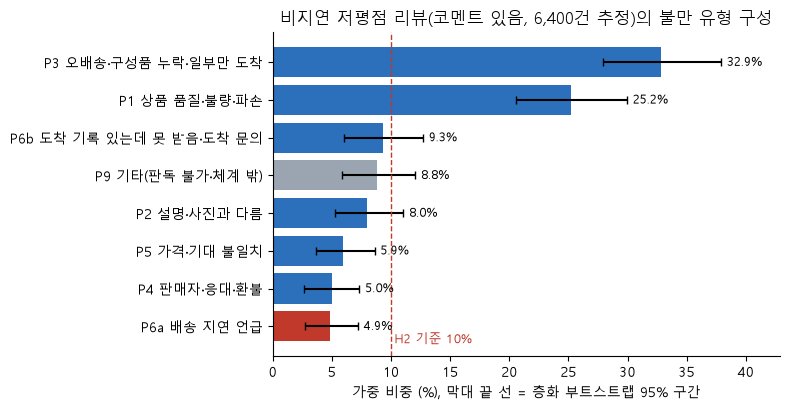

In [5]:
sh = rd("shares")
sh = sh[sh["set"] == "all310"].set_index("type").reindex(TYPES)
tbl = pd.DataFrame({
    "유형": [f"{t} {TYPE_NAME[t]}" for t in TYPES],
    "건수": sh["n"].astype(int).values,
    "가중 비중(%)": (sh["weighted"] * 100).round(1).values,
    "95% 구간": [f"{lo * 100:.1f} ~ {hi * 100:.1f}" for lo, hi in zip(sh.w_lo, sh.w_hi)],
    "비가중(%)": (sh["unweighted"] * 100).round(1).values,
}).sort_values("가중 비중(%)", ascending=False).reset_index(drop=True)
display(tbl)
assert int(sh["n"].sum()) == 310
assert (pct(sh.loc["P3", "weighted"]), pct(sh.loc["P1", "weighted"]), pct(sh.loc["P6a", "weighted"])) == (32.9, 25.2, 4.9)

o = sh.sort_values("weighted")
fig, ax = plt.subplots(figsize=(8, 4.2))
colors = ["#9aa5b1" if t == "P9" else ("#c0392b" if t == "P6a" else "#2c6fbb") for t in o.index]
ax.barh([f"{t} {TYPE_NAME[t]}" for t in o.index], o["weighted"] * 100, color=colors,
        xerr=[(o["weighted"] - o["w_lo"]) * 100, (o["w_hi"] - o["weighted"]) * 100], capsize=3)
ax.axvline(10, ls="--", lw=1, color="#c0392b")
ax.text(10.3, -0.45, "H2 기준 10%", color="#c0392b", fontsize=9)
for y, (v, hi) in enumerate(zip(o["weighted"] * 100, o["w_hi"] * 100)):
    ax.text(hi + 0.5, y, f"{v:.1f}%", va="center", fontsize=9)       # 구간 끝 오른쪽에 값 표시
ax.set_xlim(0, float(o["w_hi"].max() * 100) + 5)
ax.set_xlabel("가중 비중 (%), 막대 끝 선 = 층화 부트스트랩 95% 구간")
ax.set_title("비지연 저평점 리뷰(코멘트 있음, 6,400건 추정)의 불만 유형 구성")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "11_stage3_shares.png", dpi=150)
plt.show()

**결과.** **P3(구성품 누락·오배송·일부만 도착) 32.9%**가 가장 많고, **P1(품질·파손) 25.2%**가 뒤를 잇는다. 두 유형이 절반 이상을 차지한다. 도착 기록이 있는데 못 받았다는 불만(P6b) 9.3%, 기타(P9) 8.8%가 그다음이고, **배송 지연 언급(P6a)은 4.9%** 다. 가중 비중과 비가중 비중은 거의 같았다(층 가중치가 대부분 21 안팎으로 고르기 때문).

**해석.** late=0인데 저평점을 준 고객의 불만은 **배송 속도보다 "받은 물건"에 대한 것**이 대부분이다. 다만 이 결과는 코멘트를 남긴 리뷰에 한정된다.

## 5. 사전 가설 판정

가설과 판정 기준은 라벨링 전에 규칙 문서 §6에 적고 커밋했다(`2488274`). 판정은 모두 **점추정** 기준이고, 결과를 본 뒤 가설과 기준을 바꾸지 않았다.

| 가설 | 내용 | 판정 기준 |
|---|---|---|
| H1 | 상품 품질·불량(P1)이 최다 유형일 것 | P1 가중 비중이 P9를 뺀 다른 모든 유형보다 높음 |
| H2 | 지연이 아닌데 지연을 언급하는 불만(P6a)이 무시할 수 없을 것 | P6a 가중 비중 ≥ 10% |
| H3(탐색) | 배송비가 큰 주문일수록 배송비 불만을 더 말할 것 | 배송비(`freight_sum`) 상위 3분위의 언급 비율 > 하위 3분위. 상·하위 언급 합이 10건 미만이면 판단불가 |

In [6]:
w = sh["weighted"]
nonp9 = w.drop("P9")
h1 = nonp9.idxmax() == "P1"
h2 = w["P6a"] >= 0.10
h3t = rd("h3").set_index("tercile")
up, lo = h3t.loc["high"], h3t.loc["low"]
h3_sum = int(up.mention_true + lo.mention_true)

verdict = pd.DataFrame([
    ("H1", f"P1 {pct(w['P1'])}% vs 최다 {nonp9.idxmax()} {pct(nonp9.max())}%", "지지" if h1 else "기각"),
    ("H2", f"P6a {pct(w['P6a'])}% [{pct(sh.loc['P6a', 'w_lo'])}, {pct(sh.loc['P6a', 'w_hi'])}]", "지지" if h2 else "기각"),
    ("H3", f"언급 비율 상위 {pct(up.rate)}% ({int(up.mention_true)}/{int(up.n)}) vs 하위 {pct(lo.rate)}% "
           f"({int(lo.mention_true)}/{int(lo.n)}), 상·하위 합 {h3_sum}건", "판단불가" if h3_sum < 10 else "방향 관찰"),
], columns=["가설", "결과", "판정"])
display(verdict)
print("H3 분위별 언급(중위 포함):", h3t["mention_true"].astype(int).to_dict(), "/ U(판단 보류) 건수:", h3t["U"].astype(int).to_dict())
assert (not h1) and (not h2) and h3_sum == 5

,가설,결과,판정
0,H1,P1 25.2% vs 최다 P3 32.9%,기각
1,H2,"P6a 4.9% [2.7, 7.2]",기각
2,H3,"언급 비율 상위 1.1% (1/92) vs 하위 3.9% (4/102), 상·하위 ...",판단불가


H3 분위별 언급(중위 포함): {'low': 4, 'mid': 2, 'high': 1} / U(판단 보류) 건수: {'low': 0, 'mid': 0, 'high': 0}


**결과.** H1은 P3가 P1보다 많아 **기각**, H2는 P6a가 4.9%로 10%에 못 미쳐(구간 상한 7.2%도 10% 아래) **기각**, H3은 310건 중 배송비 언급이 7건뿐이라 **판단불가**다.

**해석.** 처음에는 "품질 불만이 가장 많고, 지연이 아닌데도 지연을 말하는 불만이 꽤 있을 것"이라고 예상했다. 실제로는 **구성·오배송 문제가 품질보다 많았고, 지연 언급은 적었다.** 가설이 틀린 것 자체가 이 단계의 결과다. 참고로 부트스트랩 재표본 중 P1이 최다였던 비율은 3.0%였다(`report_stage3.py`).

## 6. 민감도: 분석기간 끝(2018년 8월, 7\~8월)을 빼도 같은가

**왜 보나.** 분석기간 끝인 2018년 8월에는 오른쪽 절단(D-17) 때문에 일부 주문만 남아 있다. 이 구간이 결과를 좌우하지 않는지 보려고, 라벨링 전에 "8월 제외"를 민감도로 정해 두었다(규칙 문서 §8).

**방법.** 대상 6,400건에서 해당 월을 빼고 층 모집단 건수를 다시 센 뒤 남은 표본으로 재가중했다(D-35에서 §8 방식으로 바로잡음).

In [7]:
se = rd("sens")
piv = (se.pivot(index="type", columns="set", values="weighted").reindex(TYPES) * 100).round(1)
piv = piv[["all310", "2018-08 제외", "2018-07·08 제외"]].rename(columns={"all310": "전체(310건)"})
n_set = se.groupby("set")["n"].sum()
piv.columns = [f"{c} n={int(n_set[s])}" for c, s in zip(piv.columns, ["all310", "2018-08 제외", "2018-07·08 제외"])]
display(piv)
for s in ["2018-08 제외", "2018-07·08 제외"]:
    x = se[se["set"] == s].set_index("type")["weighted"]
    print(f"{s}: 최다 {x.drop('P9').idxmax()}, P1 {pct(x['P1'])}%, P6a {pct(x['P6a'])}% → H1 기각, H2 기각 유지")
aug = se[se["set"] == "2018-08 제외"].set_index("type")["weighted"]
assert (pct(aug["P1"]), pct(aug["P6a"])) == (25.5, 5.1), \
    "8월 제외 값이 D-35 이전 값입니다. 수정된 stage3_results.py로 다시 집계했는지 확인"

,전체(310건) n=310,2018-08 제외 n=294,2018-07·08 제외 n=274
type,,,
P1,25.2,25.5,24.8
P2,8.0,8.1,8.3
P3,32.9,32.6,33.2
P4,5.0,4.9,5.3
P5,5.9,6.0,4.9
P6a,4.9,5.1,5.5
P6b,9.3,9.4,9.1
P9,8.8,8.4,8.9


2018-08 제외: 최다 P3, P1 25.5%, P6a 5.1% → H1 기각, H2 기각 유지
2018-07·08 제외: 최다 P3, P1 24.8%, P6a 5.5% → H1 기각, H2 기각 유지


**결과.** 8월을 빼도(P1 25.5%, P3 32.6%, P6a 5.1%), 7\~8월을 빼도(P1 24.8%, P3 33.2%, P6a 5.5%) 순위와 판정이 그대로다. 분석기간 끝의 특이성이 결론을 바꾸지 않는다.

## 7. 교차분석: 어떤 주문에서 어떤 불만이 나오나

**무엇을 했나.** 라벨링 전에 정해 둔 교차(규칙 문서 §7): 배송비 3분위·분기(주), 주문 상품 수·셀러 수(부). 라벨링이 끝날 때까지 교차 변수 파일을 열지 않았다. 표는 가중 비중(%)이고 괄호는 표본 건수다. 칸 건수가 15 미만이면 불안정하게 읽는다.

주문 상품 수


,1 (n=225),2+ (n=85)
type,,
P1,32.2 (72),6.9 (6)
P2,11.1 (24),0.0 (0)
P3,17.5 (40),73.2 (62)
P4,5.5 (12),3.6 (3)
P5,7.7 (19),1.2 (1)
P6a,6.4 (15),0.9 (1)
P6b,9.2 (20),9.7 (8)
P9,10.5 (23),4.5 (4)


셀러 수


,1 (n=283),2+ (n=27)
type,,
P1,27.3 (77),3.7 (1)
P2,8.8 (24),0.0 (0)
P3,28.8 (82),74.0 (20)
P4,5.1 (14),3.7 (1)
P5,6.5 (20),0.0 (0)
P6a,5.3 (16),0.0 (0)
P6b,8.8 (24),14.9 (4)
P9,9.3 (26),3.7 (1)


배송비 3분위 (low ≤ 15.94 < mid ≤ 28.19 < high)


,low (n=102),mid (n=116),high (n=92)
type,,,
P1,39.7 (41),21.4 (24),13.6 (13)
P2,10.0 (10),10.8 (12),2.2 (2)
P3,17.4 (18),26.3 (31),58.3 (53)
P4,4.0 (4),5.4 (6),5.6 (5)
P5,6.6 (7),6.5 (9),4.5 (4)
P6a,4.0 (4),5.8 (7),4.6 (5)
P6b,9.1 (9),9.8 (11),9.0 (8)
P9,9.1 (9),13.9 (16),2.2 (2)


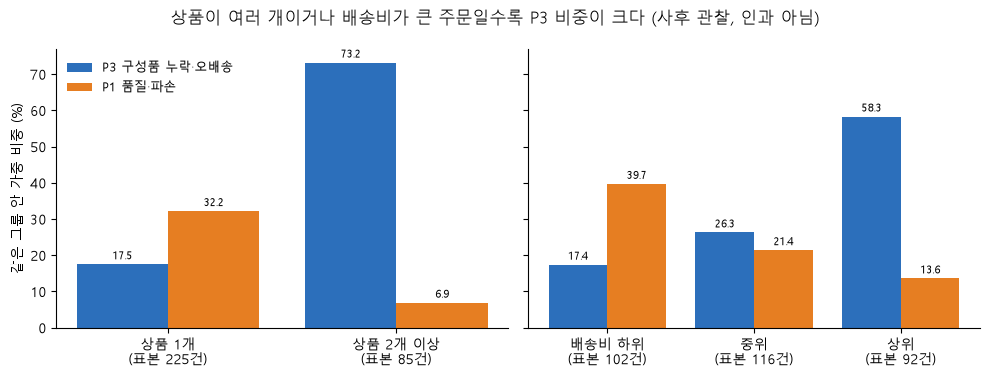

In [8]:
cr = rd("cross")

def cross_tbl(name, order):
    t = cr[cr["cross"] == name]
    p = (t.pivot(index="type", columns="group", values="weighted").reindex(TYPES)[order] * 100).round(1)
    n = t.pivot(index="type", columns="group", values="n").reindex(TYPES)[order].astype(int)
    ng = t.groupby("group")["n_group"].first()[order]
    out = p.astype(str) + " (" + n.astype(str) + ")"
    out.columns = [f"{g} (n={int(ng[g])})" for g in order]
    return out, p

items_tbl, items_p = cross_tbl("부: n_items", ["1", "2+"])
sellers_tbl, _ = cross_tbl("부: n_sellers", ["1", "2+"])
freight_tbl, freight_p = cross_tbl("주: freight_sum 3분위", ["low", "mid", "high"])
print("주문 상품 수"); display(items_tbl)
print("셀러 수"); display(sellers_tbl)
print("배송비 3분위 (low ≤ 15.94 < mid ≤ 28.19 < high)"); display(freight_tbl)
assert (items_p.loc["P3", "2+"], items_p.loc["P3", "1"]) == (73.2, 17.5)

ng = lambda name: cr[cr["cross"] == name].groupby("group")["n_group"].first()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (p, order, lab, name) in zip(axes, [
        (items_p, ["1", "2+"], ["상품 1개", "상품 2개 이상"], "부: n_items"),
        (freight_p, ["low", "mid", "high"], ["배송비 하위", "중위", "상위"], "주: freight_sum 3분위")]):
    x = np.arange(len(order))
    for dx, t, col, lb in [(-0.2, "P3", "#2c6fbb", "P3 구성품 누락·오배송"), (0.2, "P1", "#e67e22", "P1 품질·파손")]:
        bars = ax.bar(x + dx, p.loc[t, order], 0.4, label=lb, color=col)
        ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
    n_g = ng(name)
    ax.set_xticks(x, [f"{l}\n(표본 {int(n_g[g])}건)" for l, g in zip(lab, order)])
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("같은 그룹 안 가중 비중 (%)")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("상품이 여러 개이거나 배송비가 큰 주문일수록 P3 비중이 크다 (사후 관찰, 인과 아님)")
fig.tight_layout()
fig.savefig(FIG / "11_stage3_cross_p3_p1.png", dpi=150)
plt.show()

**결과.** 상품이 2개 이상인 주문에서는 P3가 **73.2%**(85건 중 62건)인 반면, 1개짜리 주문에서는 17.5%다. 셀러가 2명 이상인 주문도 P3가 74.0%다. 1개짜리 주문에서는 P1(32.2%)이 가장 많다. 배송비 상위 분위의 P3 비중(58.3%)이 하위(17.4%)보다 큰 것도 같은 모습이다.

**해석(사후 탐색).** 교차 항목은 미리 정했지만 "P3가 여러 상품 주문에 몰린다"는 해석은 결과를 본 뒤 나왔고, 다중비교 보정을 하지 않았다. 또 **P3 정의에 "구성품 누락·일부만 도착"이 들어 있어서**, 상품이 여러 개인 주문에서 P3가 많은 것은 일부 정의에서 오는 결과다. 배송비 분위 차이도 "상품이 많을수록 배송비 합이 크다"는 효과와 섞여 있어 배송비의 효과로 읽지 않는다. 분기별 표(`stage3_results_cross.csv`, `주: 분기`)는 칸 건수가 작아(예: 2017Q1 P6b 1건) 추세로 읽지 않는다.

**활용 아이디어(검증 전).** 여러 상품·여러 셀러 주문은 출고 단계에서 구성 확인을 강화할 후보다. 이를 주장하려면 별도 사전 등록 가설과 정의상 겹침을 뺀 설계가 필요하다.

## 8. P6b("못 받았다"): 도착 전에 쓴 리뷰인가

**왜 보나.** P6b는 도착 기록이 있는데 "아직 못 받았다"거나 "언제 오냐"는 불만이다. 리뷰를 도착 **전에** 썼다면 단순히 배송 중이었을 수 있으므로, 응답 시각(`review_answer_timestamp`)과 도착 시각을 비교해 나눴다.

In [9]:
p6 = rd("p6b").set_index("split")
display(p6.assign(weighted=(p6["weighted"] * 100).round(1)).rename(
    index={"before": "도착 전 응답", "after": "도착 후 응답"}, columns={"n": "건수", "weighted": "가중 비중(%)"}))
assert int(p6.loc["before", "n"]) == 0 and int(p6.loc["after", "n"]) == 28

,건수,가중 비중(%)
split,,
도착 전 응답,0,0.0
도착 후 응답,28,9.3


**결과.** P6b 28건은 **모두 도착 기록 이후에 쓴 리뷰**다(310건 전체가 도착 후 응답이고, 6,400건 중 도착 전 응답은 15건뿐이라 표본에서 0건은 자연스럽다).

**해석.** "배송 중이라 아직 안 온 것"으로는 설명되지 않는다. 다만 도착 기록이 실제 수령과 다른지(오배달·대리 수령 등)는 데이터로 확인할 수 없으므로 "고객이 실제로 못 받았다"고 단정하지 않는다.

## 9. 결론과 한계

### 결론
1. 코멘트를 남긴 비지연 저평점 리뷰의 불만은 **받은 물건의 문제**(구성품 누락·오배송 32.9%, 품질·파손 25.2%)가 중심이고, **배송 지연 언급은 4.9%** 에 그친다.
2. 사전 가설 H1(P1 최다)과 H2(P6a ≥ 10%)는 **기각**, H3(배송비 언급)는 **판단불가**. 8월·7\~8월을 빼도 판정은 같다.
3. 구성품 누락·오배송(P3)은 **여러 상품·여러 셀러 주문에 몰려 있다**(사후 관찰, 일부는 정의에서 오는 결과).
4. 키워드 규칙은 정밀도는 쓸 만하지만(P1 0.89, P3 0.78) **P1 재현율이 0.50**이라, 6,400건 전체 확장에는 아직 쓰기 어렵다.

### 한계 (자세한 내용은 `docs/stage3_results.md` 3절)
- **범위**: 코멘트를 남긴 리뷰만 본다(대상 안 코멘트 작성률 1점 81.8%, 2점 69.1%). 비교 집단이 없어 "경보가 놓친 이유" 같은 인과는 말하지 않는다. 도착일이 없는 주문(2,888건, 2.9%)은 대상 밖이다.
- **라벨**: 라벨러 한 명, 신뢰도는 자기 일관성(kappa 0.864)뿐이다. 소수 유형(P4·P6a·P9)의 일관성은 검증되지 않았다. 공식 라벨 중 4건(dev 1\~50 재라벨)은 AI 제안을 받은 뒤 직접 입력했다.
- **번역**: 기계 번역을 거쳤고 번역 정확도는 정량 평가하지 않았다.
- **소표본**: P2·P4·P5·P6a·P6b는 건수가 적어 구간이 넓다.
- **계획 대비 하지 않은 것**: 규칙 확장 비중 병기, 4-6 추가 라벨링, 정형+텍스트 결합 모델(선택 과제), LeIA 활용(계획서에서 보조로 변경 후 미사용).
- **절차**: 평가·집계를 계획보다 먼저 실행했고, 8월 민감도는 처음에 규칙 문서와 다른 근사로 계산했다가 바로잡았다. 결과를 본 뒤 가설·기준·코드북·규칙은 바꾸지 않았다(D-34, D-35).